adaboost regression

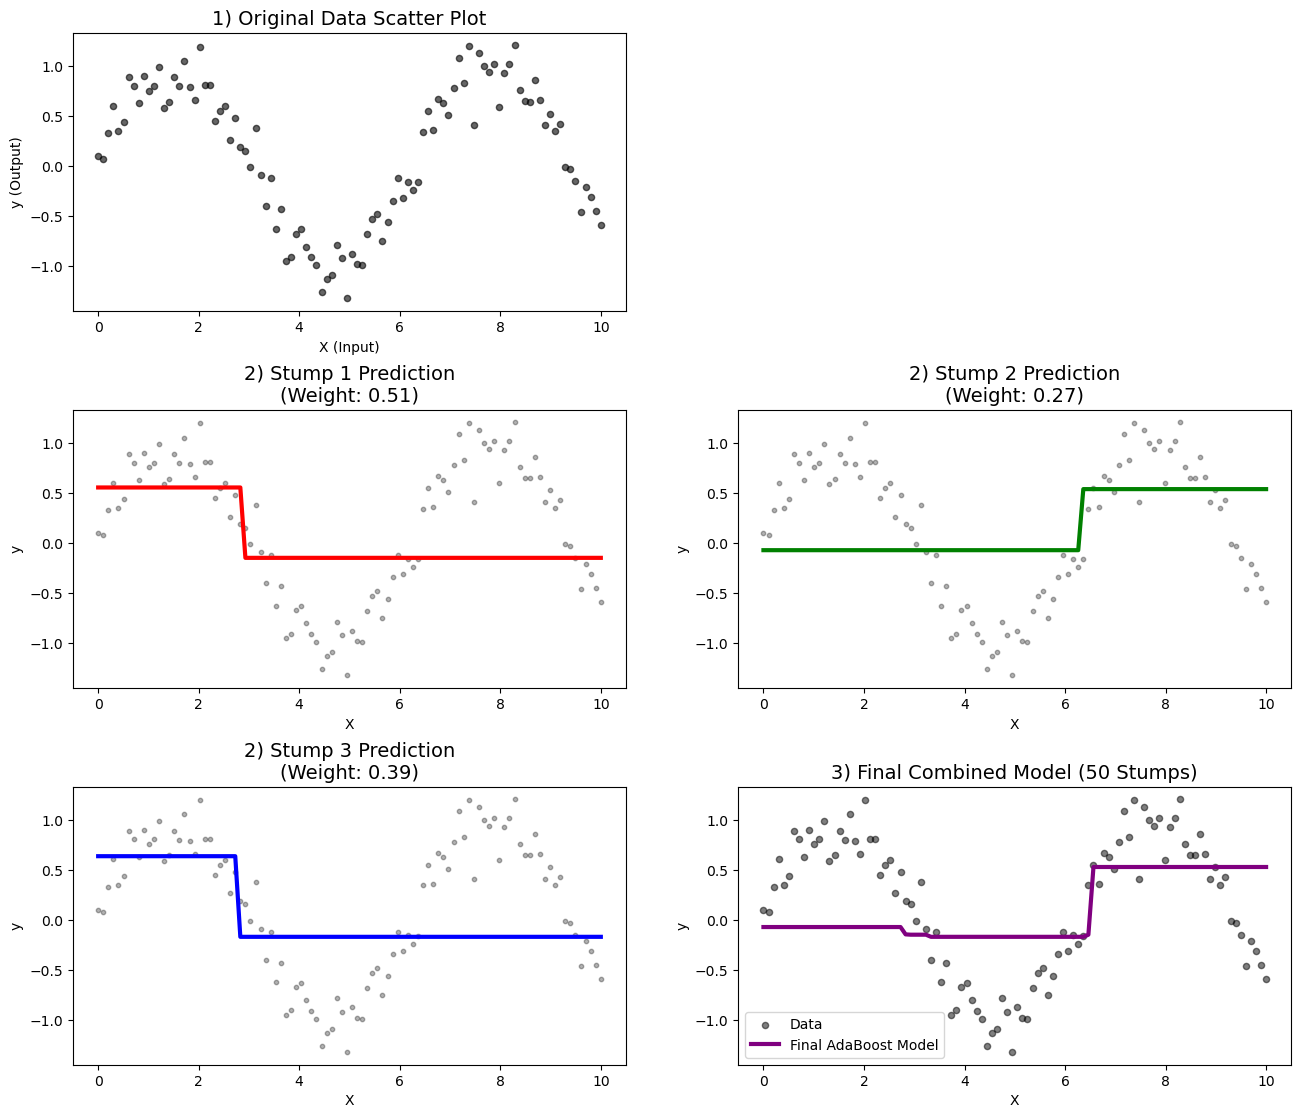

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor

# ==========================================
# 1. Generate 1D Data (1 input, 1 output)
# ==========================================
np.random.seed(42)
# Input variable (X) and Output variable (y)
X = np.linspace(0, 10, 100)[:, np.newaxis]
# True function is a sine wave, adding some random noise
y = np.sin(X).ravel() + np.random.normal(0, 0.2, X.shape[0])

# ==========================================
# 2. Train the AdaBoost Model
# ==========================================
# A "stump" is a decision tree with max_depth=1
stump = DecisionTreeRegressor(max_depth=1)

# Fit AdaBoost with 50 stumps
ada_model = AdaBoostRegressor(estimator=stump, n_estimators=50, random_state=42)
ada_model.fit(X, y)

# Extract predictions for the first 3 individual stumps
y_pred_stump1 = ada_model.estimators_[0].predict(X)
y_pred_stump2 = ada_model.estimators_[1].predict(X)
y_pred_stump3 = ada_model.estimators_[2].predict(X)

# Extract prediction for the final combined model
y_pred_final = ada_model.predict(X)

# ==========================================
# 3. Plotting the Results
# ==========================================
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
fig.tight_layout(pad=5.0)

# Plot 1: The original data
axes[0, 0].scatter(X, y, color='black', s=20, alpha=0.6)
axes[0, 0].set_title("1) Original Data Scatter Plot", fontsize=14)
axes[0, 0].set_xlabel("X (Input)")
axes[0, 0].set_ylabel("y (Output)")

# Plot 2.1: Stump 1
axes[1, 0].scatter(X, y, color='black', s=10, alpha=0.3)
axes[1, 0].plot(X, y_pred_stump1, color='red', linewidth=3)
axes[1, 0].set_title(f"2) Stump 1 Prediction\n(Weight: {ada_model.estimator_weights_[0]:.2f})", fontsize=14)
axes[1, 0].set_xlabel("X")
axes[1, 0].set_ylabel("y")

# Plot 2.2: Stump 2
axes[1, 1].scatter(X, y, color='black', s=10, alpha=0.3)
axes[1, 1].plot(X, y_pred_stump2, color='green', linewidth=3)
axes[1, 1].set_title(f"2) Stump 2 Prediction\n(Weight: {ada_model.estimator_weights_[1]:.2f})", fontsize=14)
axes[1, 1].set_xlabel("X")
axes[1, 1].set_ylabel("y")

# Plot 2.3: Stump 3
axes[2, 0].scatter(X, y, color='black', s=10, alpha=0.3)
axes[2, 0].plot(X, y_pred_stump3, color='blue', linewidth=3)
axes[2, 0].set_title(f"2) Stump 3 Prediction\n(Weight: {ada_model.estimator_weights_[2]:.2f})", fontsize=14)
axes[2, 0].set_xlabel("X")
axes[2, 0].set_ylabel("y")

# Plot 3: Final Combination Model (All 50 Stumps)
axes[2, 1].scatter(X, y, color='black', s=20, alpha=0.5, label="Data")
axes[2, 1].plot(X, y_pred_final, color='purple', linewidth=3, label="Final AdaBoost Model")
axes[2, 1].set_title("3) Final Combined Model (50 Stumps)", fontsize=14)
axes[2, 1].set_xlabel("X")
axes[2, 1].set_ylabel("y")
axes[2, 1].legend()

# Hide the empty subplot at [0, 1] for visual symmetry
axes[0, 1].axis('off')

plt.show()

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor

# ==========================================
# 1. Create a Small Dataset (n = 6)
# ==========================================
# Adjusted to a noisy step pattern to prevent early stopping
X_train = np.array([[1], [2], [3], [4], [5], [6]])
y_train = np.array([1.0, 1.2, 1.5, 4.0, 4.2, 3.8])

# Continuous X for plotting the step functions smoothly
X_plot = np.linspace(0, 7, 200)[:, np.newaxis]

# ==========================================
# 2. Train the AdaBoost Model
# ==========================================
# Base estimator is a stump (1 split only)
stump = DecisionTreeRegressor(max_depth=1)

# Fit AdaBoost 
ada_model = AdaBoostRegressor(estimator=stump, n_estimators=10, random_state=42)
ada_model.fit(X_train, y_train)

# Predict on the continuous X_plot to show the step shapes
y_pred_stump1 = ada_model.estimators_[0].predict(X_plot)
y_pred_stump2 = ada_model.estimators_[1].predict(X_plot)
y_pred_stump3 = ada_model.estimators_[2].predict(X_plot)

# Final combined prediction
y_pred_final = ada_model.predict(X_plot)

# ==========================================
# 3. Plotting the Results
# ==========================================
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
fig.tight_layout(pad=5.0)

# Plot 1: The original small dataset
axes[0, 0].scatter(X_train, y_train, color='black', s=100, zorder=5)
axes[0, 0].set_title("1) Small Dataset (n=6)", fontsize=14)
axes[0, 0].set_xlabel("X (Input)")
axes[0, 0].set_ylabel("y (Output)")
axes[0, 0].set_xlim(0, 7)
axes[0, 0].set_ylim(0, 5)

# Plot 2.1: Stump 1
axes[1, 0].scatter(X_train, y_train, color='black', s=100, zorder=5)
axes[1, 0].plot(X_plot, y_pred_stump1, color='red', linewidth=3)
axes[1, 0].set_title(f"2) Stump 1 (Weight: {ada_model.estimator_weights_[0]:.2f})\nFinds the single best average split", fontsize=14)
axes[1, 0].set_xlim(0, 7)
axes[1, 0].set_ylim(0, 5)

# Plot 2.2: Stump 2
axes[1, 1].scatter(X_train, y_train, color='black', s=100, zorder=5)
axes[1, 1].plot(X_plot, y_pred_stump2, color='green', linewidth=3)
axes[1, 1].set_title(f"2) Stump 2 (Weight: {ada_model.estimator_weights_[1]:.2f})\nFocuses on points Stump 1 missed", fontsize=14)
axes[1, 1].set_xlim(0, 7)
axes[1, 1].set_ylim(0, 5)

# Plot 2.3: Stump 3
axes[2, 0].scatter(X_train, y_train, color='black', s=100, zorder=5)
axes[2, 0].plot(X_plot, y_pred_stump3, color='blue', linewidth=3)
axes[2, 0].set_title(f"2) Stump 3 (Weight: {ada_model.estimator_weights_[2]:.2f})\nFocuses on remaining errors", fontsize=14)
axes[2, 0].set_xlim(0, 7)
axes[2, 0].set_ylim(0, 5)

# Plot 3: Final Combination Model 
axes[2, 1].scatter(X_train, y_train, color='black', s=100, label="Data", zorder=5)
axes[2, 1].plot(X_plot, y_pred_final, color='purple', linewidth=3, label="Final Ensemble")
axes[2, 1].set_title("3) Final Combined Model\n(Weighted Median of all Stumps)", fontsize=14)
axes[2, 1].set_xlim(0, 7)
axes[2, 1].set_ylim(0, 5)
axes[2, 1].legend()

# Hide the empty subplot
axes[0, 1].axis('off')

plt.show()

IndexError: list index out of range